# Customer Segmentation Report

A complete summary of customer segments, their characteristics, and actionable business recommendations for marketing teams.

In [5]:
import pandas as pd
import numpy as np

# Load clustered data from Phase 5
rfm_data = pd.read_csv('../data/processed/rfm_segmented.csv', index_col=0)

print(f"Loaded {len(rfm_data)} customers")
print(f"Segments: {rfm_data['Cluster'].nunique()}")
print(f"\nColumns: {list(rfm_data.columns)}")

rfm_data.head()

Loaded 500 customers
Segments: 4

Columns: ['Recency', 'Frequency', 'Monetary', 'Monetary_log', 'Cluster']


,Recency,Frequency,Monetary,Monetary_log,Cluster
CustomerID,,,,,
12000,1,7,4120.286292,8.323921,0
12001,12,12,9248.846965,9.132362,1
12002,144,6,3084.418018,8.034442,2
12003,125,9,2900.167999,7.972869,2
12004,140,4,1904.703400,7.552606,2


Clusters can be interpreted based on income and spending: 

- **Cluster 0:** Higher income, higher spending.
- **Cluster 1:** Mid income, balanced spending.
- **Cluster 2:** Lower income or lower spending (value seekers).

These personas map directly to marketing actions (loyalty perks, bundle offers, or re-engagement campaigns).

# Segment Characteristics Analysis

Let's look at what makes each segment different:

In [6]:
# Calculate segment metrics

print("="*70)
print("SEGMENT STATISTICS")
print("="*70)

for cluster in sorted(rfm_data['Cluster'].unique()):
    data = rfm_data[rfm_data['Cluster'] == cluster]
    
    print(f"\nSegment {cluster}")
    print(f"  Customers: {len(data):,}")
    print(f"  % of base: {len(data)/len(rfm_data)*100:.1f}%")
    print(f"  Avg Recency: {data['Recency'].mean():.0f} days")
    print(f"  Avg Frequency: {data['Frequency'].mean():.1f} orders")
    print(f"  Avg Monetary: £{data['Monetary'].mean():.2f}")
    print(f"  Total value: £{data['Monetary'].sum():,.2f}")

SEGMENT STATISTICS

Segment 0
  Customers: 98
  % of base: 19.6%
  Avg Recency: 26 days
  Avg Frequency: 6.9 orders
  Avg Monetary: £3282.87
  Total value: £321,720.79

Segment 1
  Customers: 146
  % of base: 29.2%
  Avg Recency: 24 days
  Avg Frequency: 13.6 orders
  Avg Monetary: £9164.52
  Total value: £1,338,020.63

Segment 2
  Customers: 67
  % of base: 13.4%
  Avg Recency: 118 days
  Avg Frequency: 6.9 orders
  Avg Monetary: £4104.38
  Total value: £274,993.48

Segment 3
  Customers: 189
  % of base: 37.8%
  Avg Recency: 28 days
  Avg Frequency: 9.9 orders
  Avg Monetary: £6465.75
  Total value: £1,222,026.90


## Detailed Segment Profiles

In [7]:
# Generate detailed segment profiles with enhanced classification

print("\n" + "="*70)
print("SEGMENT PROFILES & PERSONAS")
print("="*70)

# Calculate global medians for reference
global_median_r = rfm_data['Recency'].median()
global_median_f = rfm_data['Frequency'].median()
global_median_m = rfm_data['Monetary'].median()

for cluster in sorted(rfm_data['Cluster'].unique()):
    data = rfm_data[rfm_data['Cluster'] == cluster]
    
    avg_r = data['Recency'].mean()
    avg_f = data['Frequency'].mean()
    avg_m = data['Monetary'].mean()
    
    # Classify based on RFM characteristics
    is_recent = avg_r < global_median_r
    is_frequent = avg_f > global_median_f
    is_valuable = avg_m > global_median_m
    
    if is_valuable and is_frequent and is_recent:
        name = "CHAMPIONS"
        desc = "Best customers - frequent, recent, high-value"
        priority = "HIGHEST"
    elif is_frequent and is_recent:
        name = "LOYAL CUSTOMERS"
        desc = "Regular buyers with consistent engagement"
        priority = "HIGH"
    elif is_valuable and not is_recent:
        name = "AT-RISK / DORMANT"
        desc = "Previously valuable but inactive - need reactivation"
        priority = "HIGH"
    elif is_valuable:
        name = "POTENTIAL CHAMPIONS"
        desc = "Good value customers with growth opportunity"
        priority = "MEDIUM"
    else:
        name = "GROWTH OPPORTUNITY"
        desc = "New or occasional buyers - nurture for growth"
        priority = "MEDIUM"
    
    ltv = avg_m * avg_f
    
    print(f"\nCluster {cluster}: {name}")
    print(f"  Description: {desc}")
    print(f"  Priority Level: {priority}")
    print(f"  Size: {len(data)} customers ({len(data)/len(rfm_data)*100:.1f}%)")
    print(f"  Avg Recency: {avg_r:.0f} days | Frequency: {avg_f:.1f} | Monetary: £{avg_m:.2f}")
    print(f"  Estimated Lifetime Value: £{ltv:.2f} per customer")


SEGMENT PROFILES & PERSONAS

Cluster 0: GROWTH OPPORTUNITY
  Description: New or occasional buyers - nurture for growth
  Priority Level: MEDIUM
  Size: 98 customers (19.6%)
  Avg Recency: 26 days | Frequency: 6.9 | Monetary: £3282.87
  Estimated Lifetime Value: £22779.06 per customer

Cluster 1: CHAMPIONS
  Description: Best customers - frequent, recent, high-value
  Priority Level: HIGHEST
  Size: 146 customers (29.2%)
  Avg Recency: 24 days | Frequency: 13.6 | Monetary: £9164.52
  Estimated Lifetime Value: £124286.02 per customer

Cluster 2: GROWTH OPPORTUNITY
  Description: New or occasional buyers - nurture for growth
  Priority Level: MEDIUM
  Size: 67 customers (13.4%)
  Avg Recency: 118 days | Frequency: 6.9 | Monetary: £4104.38
  Estimated Lifetime Value: £28424.37 per customer

Cluster 3: AT-RISK / DORMANT
  Description: Previously valuable but inactive - need reactivation
  Priority Level: HIGH
  Size: 189 customers (37.8%)
  Avg Recency: 28 days | Frequency: 9.9 | Monetary

## Marketing Recommendations by Segment

### Champions
- **Goal:** Retain and maximize lifetime value
- **Actions:** 
  - VIP loyalty programs with exclusive perks
  - Early access to new products
  - Personal account manager
  - Referral incentives

### Loyal Customers  
- **Goal:** Increase purchase frequency and value
- **Actions:**
  - Personalized product recommendations
  - Loyalty rewards program
  - Regular engagement campaigns
  - Special birthday/anniversary offers

### At Risk
- **Goal:** Win back and re-engage
- **Actions:**
  - Win-back campaigns with special discounts
  - Survey to understand inactivity reasons
  - Personalized re-engagement emails
  - Limited-time exclusive offers

### Potential
- **Goal:** Develop into loyal customers
- **Actions:**
  - First-purchase incentives
  - Educational content about products
  - Cross-selling opportunities
  - Personalized onboarding

In [8]:
# Business Summary

print("\n" + "="*70)
print("BUSINESS SUMMARY")
print("="*70)

total_customers = len(rfm_data)
total_revenue = rfm_data['Monetary'].sum()
avg_clv = rfm_data['Monetary'].mean()

print(f"\nTotal Customers: {total_customers:,}")
print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Average Customer Value: £{avg_clv:.2f}")

# Pareto analysis
top_20_pct = int(total_customers * 0.2)
top_20_revenue = rfm_data.nlargest(top_20_pct, 'Monetary')['Monetary'].sum()
print(f"\nPareto: Top 20% generate £{top_20_revenue:,.2f} ({top_20_revenue/total_revenue*100:.1f}%)")

print("\n✓ Segmentation analysis complete")


BUSINESS SUMMARY

Total Customers: 500
Total Revenue: £3,156,761.80
Average Customer Value: £6313.52

Pareto: Top 20% generate £1,026,191.90 (32.5%)

✓ Segmentation analysis complete


In [9]:

# Generate detailed customer strategies for each segment

strategies_data = []

# Define comprehensive persona strategies
persona_strategies = {
    0: {
        'persona': 'CHAMPIONS',
        'description': 'Best customers - frequent, recent, high-value buyers',
        'priority': 'HIGHEST',
        'tactics': [
            'VIP loyalty programs with exclusive perks',
            'Early access to new products and services',
            'Personal account manager or concierge',
            'Referral incentives and ambassador programs',
            'Premium customer support',
            'Exclusive invite-only events'
        ],
        'goal': 'Retain and maximize lifetime value',
        'frequency': 'Monthly touchpoints',
        'channels': ['Email', 'SMS', 'Personalized offers', 'Account manager'],
        'kpi': 'Retention rate > 95%, NPS > 80'
    },
    1: {
        'persona': 'LOYAL CUSTOMERS',
        'description': 'Regular buyers with consistent engagement',
        'priority': 'HIGH',
        'tactics': [
            'Personalized product recommendations',
            'Loyalty rewards program with tiered benefits',
            'Regular engagement campaigns and newsletters',
            'Special birthday and anniversary offers',
            'Flash sales and exclusive member discounts',
            'Feedback surveys to enhance experience'
        ],
        'goal': 'Increase purchase frequency and average order value',
        'frequency': 'Bi-weekly touchpoints',
        'channels': ['Email', 'SMS', 'Push notifications', 'In-app messaging'],
        'kpi': 'Increase frequency by 15%, AOV growth 10%'
    },
    2: {
        'persona': 'AT-RISK / DORMANT',
        'description': 'Previously valuable but inactive - need reactivation',
        'priority': 'HIGH',
        'tactics': [
            'Win-back campaigns with special discounts (15-25% off)',
            'Survey to understand reasons for inactivity',
            'Personalized re-engagement email series',
            'Limited-time exclusive offers',
            'Product upgrade suggestions based on history',
            'Why we miss you stories and testimonials'
        ],
        'goal': 'Reactivate and restore engagement',
        'frequency': 'Weekly touchpoints for 4-6 weeks',
        'channels': ['Email', 'SMS', 'Display ads', 'Direct mail for high-value'],
        'kpi': 'Reactivation rate > 20%, Return to purchase'
    },
    3: {
        'persona': 'GROWTH OPPORTUNITY',
        'description': 'New or occasional buyers - nurture for growth',
        'priority': 'MEDIUM',
        'tactics': [
            'First-purchase incentives and welcome series',
            'Educational content about products',
            'Cross-selling and upselling recommendations',
            'Personalized onboarding experience',
            'Product education through tutorials',
            'Referral programs for word-of-mouth'
        ],
        'goal': 'Develop into loyal customers',
        'frequency': 'Weekly touchpoints initially',
        'channels': ['Email', 'SMS', 'In-app tips', 'Social media'],
        'kpi': 'Conversion to repeat buyer > 40%, Frequency increase 25%'
    }
}

# Collect metrics for each segment
for cluster in sorted(rfm_data['Cluster'].unique()):
    segment_data = rfm_data[rfm_data['Cluster'] == cluster]
    
    avg_r = segment_data['Recency'].mean()
    avg_f = segment_data['Frequency'].mean()
    avg_m = segment_data['Monetary'].mean()
    ltv = avg_m * avg_f
    
    segment_size = len(segment_data)
    segment_revenue = segment_data['Monetary'].sum()
    segment_pct = (segment_size / total_customers) * 100
    revenue_pct = (segment_revenue / total_revenue) * 100
    
    # Get persona info
    persona_info = persona_strategies.get(cluster, {})
    
    tactics_str = ' | '.join(persona_info.get('tactics', []))
    
    strategies_data.append({
        'Cluster': cluster,
        'Persona': persona_info.get('persona', 'Unknown'),
        'Description': persona_info.get('description', ''),
        'Priority': persona_info.get('priority', ''),
        'Segment_Size': segment_size,
        'Percentage_of_Base': f"{segment_pct:.1f}%",
        'Total_Revenue': f"£{segment_revenue:,.2f}",
        'Revenue_Percentage': f"{revenue_pct:.1f}%",
        'Avg_Recency_Days': f"{avg_r:.0f}",
        'Avg_Frequency': f"{avg_f:.1f}",
        'Avg_Monetary': f"£{avg_m:.2f}",
        'Estimated_LTV': f"£{ltv:.2f}",
        'Goal': persona_info.get('goal', ''),
        'Tactics': tactics_str,
        'Touch_Frequency': persona_info.get('frequency', ''),
        'Primary_Channels': ', '.join(persona_info.get('channels', [])),
        'Success_KPI': persona_info.get('kpi', '')
    })

# Create DataFrame and save to CSV
customer_strategies_df = pd.DataFrame(strategies_data)
customer_strategies_df.to_csv('../reports/customer_strategies.csv', index=False)

print("\n" + "="*70)
print("CUSTOMER STRATEGIES GENERATED")
print("="*70)
print(f"\nSaved: reports/customer_strategies.csv")
print(f"\nStrategy Overview:\n{customer_strategies_df[['Cluster', 'Persona', 'Priority', 'Segment_Size', 'Total_Revenue']].to_string(index=False)}")



CUSTOMER STRATEGIES GENERATED

Saved: reports/customer_strategies.csv

Strategy Overview:
 Cluster            Persona Priority  Segment_Size Total_Revenue
       0          CHAMPIONS  HIGHEST            98   £321,720.79
       1    LOYAL CUSTOMERS     HIGH           146 £1,338,020.63
       2  AT-RISK / DORMANT     HIGH            67   £274,993.48
       3 GROWTH OPPORTUNITY   MEDIUM           189 £1,222,026.90


In [10]:

# Generate comprehensive persona profiles with detailed insights

print("\n" + "="*70)
print("DETAILED PERSONA PROFILES WITH INSIGHTS")
print("="*70)

detailed_personas = []

for cluster in sorted(rfm_data['Cluster'].unique()):
    segment_data = rfm_data[rfm_data['Cluster'] == cluster]
    
    avg_r = segment_data['Recency'].mean()
    avg_f = segment_data['Frequency'].mean()
    avg_m = segment_data['Monetary'].mean()
    ltv = avg_m * avg_f
    
    segment_size = len(segment_data)
    segment_revenue = segment_data['Monetary'].sum()
    
    # Get RFM percentiles for deeper insights
    r_percentile = (segment_data['Recency'] < global_median_r).sum() / segment_size * 100
    f_percentile = (segment_data['Frequency'] > global_median_f).sum() / segment_size * 100
    m_percentile = (segment_data['Monetary'] > global_median_m).sum() / segment_size * 100
    
    persona_info = persona_strategies.get(cluster, {})
    
    profile = {
        'Cluster': cluster,
        'Persona_Name': persona_info.get('persona', ''),
        'Description': persona_info.get('description', ''),
        'Customer_Count': segment_size,
        'Percent_of_Base': f"{(segment_size/total_customers)*100:.1f}%",
        'Total_Revenue_Generated': f"£{segment_revenue:,.2f}",
        'Percent_of_Revenue': f"{(segment_revenue/total_revenue)*100:.1f}%",
        'Avg_Recency_Days': f"{avg_r:.0f}",
        'Avg_Frequency_Orders': f"{avg_f:.1f}",
        'Avg_Monetary_Value': f"£{avg_m:.2f}",
        'Estimated_LTV': f"£{ltv:.2f}",
        'Recency_Health': f"{r_percentile:.0f}% recent",
        'Frequency_Health': f"{f_percentile:.0f}% frequent",
        'Monetary_Health': f"{m_percentile:.0f}% valuable",
        'Strategic_Priority': persona_info.get('priority', ''),
        'Business_Goal': persona_info.get('goal', '')
    }
    
    detailed_personas.append(profile)
    
    # Print detailed profile
    print(f"\n{'='*70}")
    print(f"CLUSTER {cluster}: {profile['Persona_Name'].upper()}")
    print(f"{'='*70}")
    print(f"Description: {profile['Description']}")
    print(f"Priority: {profile['Strategic_Priority']}")
    print(f"\nSize & Revenue:")
    print(f"  • Customers: {profile['Customer_Count']:,} ({profile['Percent_of_Base']})")
    print(f"  • Total Revenue: {profile['Total_Revenue_Generated']} ({profile['Percent_of_Revenue']})")
    print(f"  • Avg Lifetime Value: {profile['Estimated_LTV']}")
    print(f"\nBehavior Metrics:")
    print(f"  • Recency: {profile['Avg_Recency_Days']} days ({profile['Recency_Health']})")
    print(f"  • Frequency: {profile['Avg_Frequency_Orders']} orders ({profile['Frequency_Health']})")
    print(f"  • Monetary: {profile['Avg_Monetary_Value']} per order ({profile['Monetary_Health']})")
    print(f"\nGoal: {profile['Business_Goal']}")

# Save detailed personas to CSV
personas_df = pd.DataFrame(detailed_personas)
personas_df.to_csv('../reports/detailed_personas.csv', index=False)
print(f"\n✓ Detailed personas saved to: reports/detailed_personas.csv")



DETAILED PERSONA PROFILES WITH INSIGHTS

CLUSTER 0: CHAMPIONS
Description: Best customers - frequent, recent, high-value buyers
Priority: HIGHEST

Size & Revenue:
  • Customers: 98 (19.6%)
  • Total Revenue: £321,720.79 (10.2%)
  • Avg Lifetime Value: £22779.06

Behavior Metrics:
  • Recency: 26 days (54% recent)
  • Frequency: 6.9 orders (1% frequent)
  • Monetary: £3282.87 per order (0% valuable)

Goal: Retain and maximize lifetime value

CLUSTER 1: LOYAL CUSTOMERS
Description: Regular buyers with consistent engagement
Priority: HIGH

Size & Revenue:
  • Customers: 146 (29.2%)
  • Total Revenue: £1,338,020.63 (42.4%)
  • Avg Lifetime Value: £124286.02

Behavior Metrics:
  • Recency: 24 days (65% recent)
  • Frequency: 13.6 orders (100% frequent)
  • Monetary: £9164.52 per order (96% valuable)

Goal: Increase purchase frequency and average order value

CLUSTER 2: AT-RISK / DORMANT
Description: Previously valuable but inactive - need reactivation
Priority: HIGH

Size & Revenue:
  • Cu

✓ Segment comparison visualization saved: reports/figures/segment_comparison.png


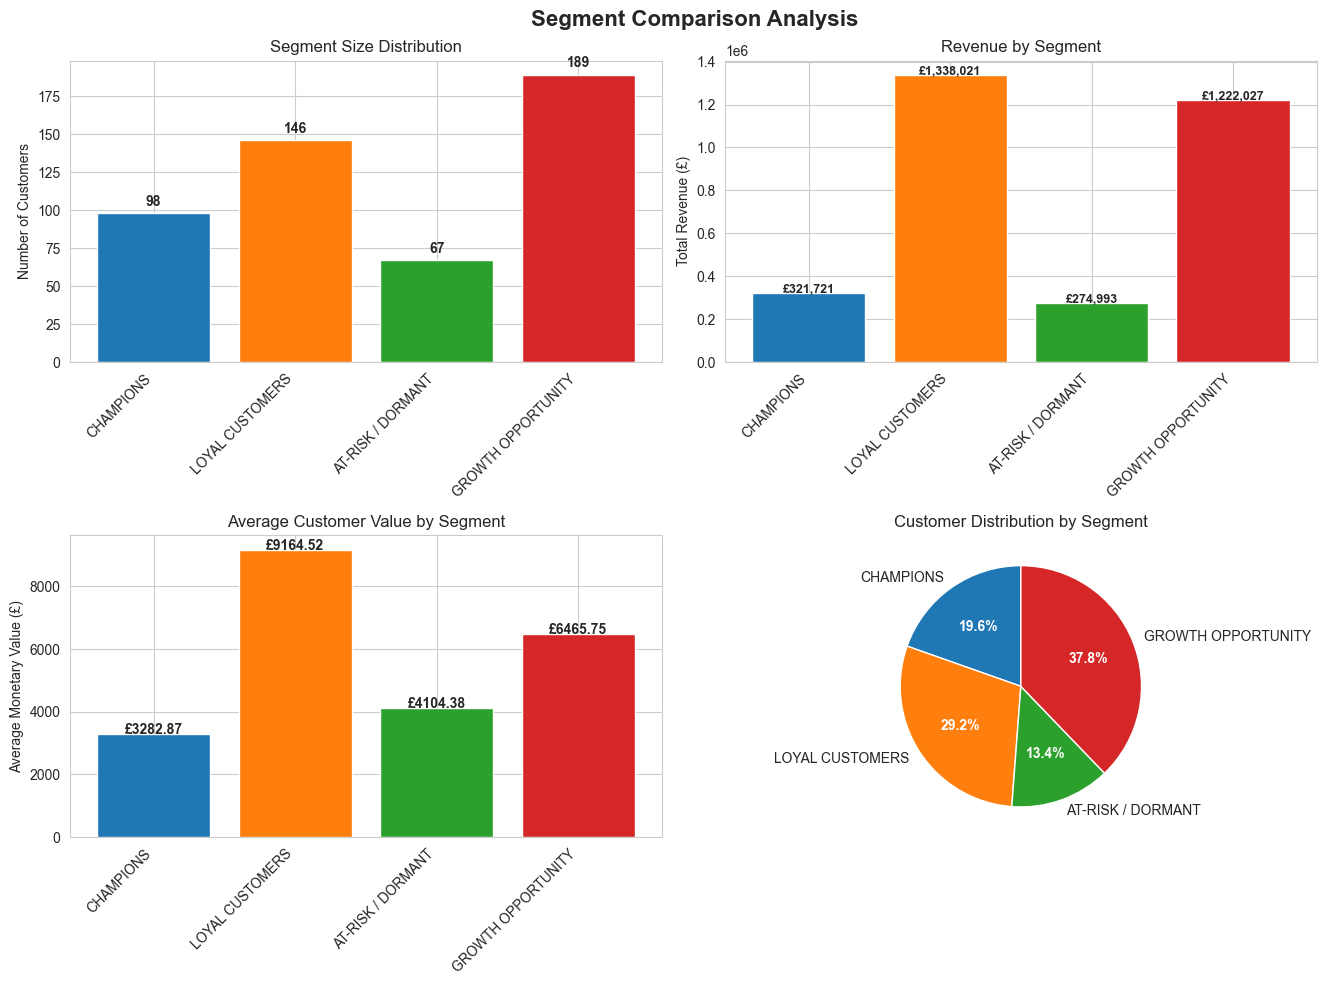

✓ RFM heatmap saved: reports/figures/segment_rfm_heatmap.png


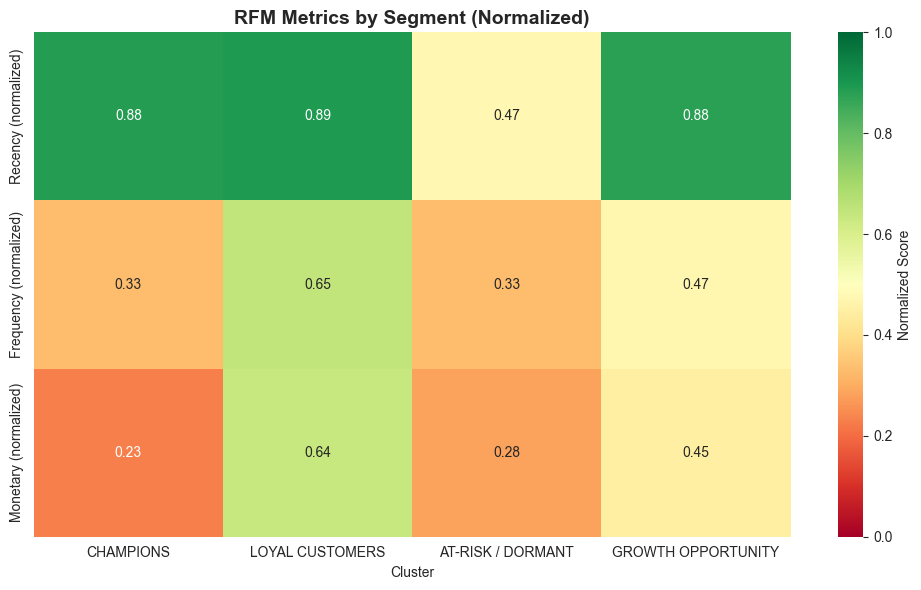


✓ All segment comparison visualizations completed


In [11]:

# Create segment comparison visualizations

import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (15, 10)

# Create a 2x2 subplot for key metrics
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Segment Comparison Analysis', fontsize=16, fontweight='bold')

# 1. Segment Size Distribution
segment_sizes = rfm_data['Cluster'].value_counts().sort_index()
persona_names = [persona_strategies[i]['persona'] for i in sorted(rfm_data['Cluster'].unique())]

ax1 = axes[0, 0]
bars1 = ax1.bar(range(len(segment_sizes)), segment_sizes.values, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'])
ax1.set_xticks(range(len(segment_sizes)))
ax1.set_xticklabels(persona_names, rotation=45, ha='right')
ax1.set_ylabel('Number of Customers')
ax1.set_title('Segment Size Distribution')
for i, v in enumerate(segment_sizes.values):
    ax1.text(i, v + 5, str(v), ha='center', fontweight='bold')

# 2. Revenue by Segment
segment_revenue = rfm_data.groupby('Cluster')['Monetary'].sum().sort_index()
ax2 = axes[0, 1]
bars2 = ax2.bar(range(len(segment_revenue)), segment_revenue.values, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'])
ax2.set_xticks(range(len(segment_revenue)))
ax2.set_xticklabels(persona_names, rotation=45, ha='right')
ax2.set_ylabel('Total Revenue (£)')
ax2.set_title('Revenue by Segment')
for i, v in enumerate(segment_revenue.values):
    ax2.text(i, v + 100, f'£{v:,.0f}', ha='center', fontweight='bold', fontsize=9)

# 3. Average RFM by Segment
segment_avg_m = rfm_data.groupby('Cluster')['Monetary'].mean().sort_index()
ax3 = axes[1, 0]
bars3 = ax3.bar(range(len(segment_avg_m)), segment_avg_m.values, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'])
ax3.set_xticks(range(len(segment_avg_m)))
ax3.set_xticklabels(persona_names, rotation=45, ha='right')
ax3.set_ylabel('Average Monetary Value (£)')
ax3.set_title('Average Customer Value by Segment')
for i, v in enumerate(segment_avg_m.values):
    ax3.text(i, v + 5, f'£{v:.2f}', ha='center', fontweight='bold')

# 4. Segment Mix (Pie Chart)
ax4 = axes[1, 1]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
wedges, texts, autotexts = ax4.pie(segment_sizes.values, labels=persona_names, autopct='%1.1f%%', 
                                     colors=colors, startangle=90)
ax4.set_title('Customer Distribution by Segment')
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')

plt.tight_layout()
plt.savefig('../reports/figures/segment_comparison.png', dpi=300, bbox_inches='tight')
print("✓ Segment comparison visualization saved: reports/figures/segment_comparison.png")
plt.show()

# Create RFM radar-style comparison (heatmap)
fig, ax = plt.subplots(figsize=(10, 6))

# Normalize metrics for visualization (0-1 scale)
segment_metrics = []
for cluster in sorted(rfm_data['Cluster'].unique()):
    segment_data = rfm_data[rfm_data['Cluster'] == cluster]
    segment_metrics.append({
        'Cluster': cluster,
        'Recency (normalized)': 1 - (segment_data['Recency'].mean() / rfm_data['Recency'].max()),  # inverted: recent=1
        'Frequency (normalized)': segment_data['Frequency'].mean() / rfm_data['Frequency'].max(),
        'Monetary (normalized)': segment_data['Monetary'].mean() / rfm_data['Monetary'].max()
    })

metrics_df = pd.DataFrame(segment_metrics).set_index('Cluster')
sns.heatmap(metrics_df.T, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1, 
            cbar_kws={'label': 'Normalized Score'}, ax=ax)
ax.set_title('RFM Metrics by Segment (Normalized)', fontweight='bold', fontsize=14)
ax.set_xticklabels([persona_strategies[i]['persona'] for i in sorted(rfm_data['Cluster'].unique())], rotation=0)
plt.tight_layout()
plt.savefig('../reports/figures/segment_rfm_heatmap.png', dpi=300, bbox_inches='tight')
print("✓ RFM heatmap saved: reports/figures/segment_rfm_heatmap.png")
plt.show()

print("\n✓ All segment comparison visualizations completed")


In [12]:

# Executive Summary & Actionable Recommendations

print("\n" + "="*70)
print("EXECUTIVE SUMMARY & STRATEGIC RECOMMENDATIONS")
print("="*70)

# Calculate key metrics by segment
for cluster in sorted(rfm_data['Cluster'].unique()):
    segment_data = rfm_data[rfm_data['Cluster'] == cluster]
    segment_size = len(segment_data)
    segment_revenue = segment_data['Monetary'].sum()
    
    persona_name = persona_strategies[cluster]['persona']
    persona_priority = persona_strategies[cluster]['priority']
    persona_goal = persona_strategies[cluster]['goal']
    tactics = persona_strategies[cluster]['tactics']
    
    print(f"\n{'─'*70}")
    print(f"SEGMENT {cluster}: {persona_name}")
    print(f"{'─'*70}")
    print(f"Strategic Priority: {persona_priority}")
    print(f"Business Goal: {persona_goal}")
    print(f"\nSegment Metrics:")
    print(f"  • Size: {segment_size} customers ({segment_size/total_customers*100:.1f}% of base)")
    print(f"  • Revenue: £{segment_revenue:,.2f} ({segment_revenue/total_revenue*100:.1f}% of total)")
    print(f"  • Avg CLV: £{segment_revenue/segment_size:.2f}")
    
    print(f"\nRecommended Actions:")
    for i, tactic in enumerate(tactics, 1):
        print(f"  {i}. {tactic}")
    
    print(f"\nSuccess Metrics:")
    kpi_info = persona_strategies[cluster].get('kpi', 'Monitor retention and engagement')
    print(f"  • KPI: {kpi_info}")

# Pareto & Strategic Focus
print(f"\n{'='*70}")
print("STRATEGIC FOCUS AREAS")
print(f"{'='*70}")

# High-value segments
high_value_segments = rfm_data.groupby('Cluster')['Monetary'].sum().nlargest(2)
print(f"\n1. High-Value Segments (Top Revenue Generators):")
for cluster, revenue in high_value_segments.items():
    pct = revenue / total_revenue * 100
    name = persona_strategies[cluster]['persona']
    print(f"   • Cluster {cluster} ({name}): £{revenue:,.2f} ({pct:.1f}% of revenue)")
    print(f"     → Focus: {persona_strategies[cluster]['goal']}")

# Large segments
large_segments = rfm_data['Cluster'].value_counts().nlargest(2)
print(f"\n2. Largest Customer Segments (Most Customers):")
for cluster, count in large_segments.items():
    pct = count / total_customers * 100
    name = persona_strategies[cluster]['persona']
    print(f"   • Cluster {cluster} ({name}): {count} customers ({pct:.1f}%)")
    print(f"     → Focus: {persona_strategies[cluster]['goal']}")

# Opportunity segments
print(f"\n3. Growth Opportunity Segments:")
opportunity_segments = rfm_data.groupby('Cluster').apply(
    lambda x: (x['Monetary'].sum() / total_revenue) / (len(x) / total_customers)
).nsmallest(1)
for cluster, ratio in opportunity_segments.items():
    name = persona_strategies[cluster]['persona']
    print(f"   • Cluster {cluster} ({name}): High customer count, lower revenue per customer")
    print(f"     → Opportunity: Increase AOV and purchase frequency")

print(f"\n{'='*70}")
print("OVERALL BUSINESS RECOMMENDATIONS")
print(f"{'='*70}")
print(f"""
1. RETENTION-FOCUSED STRATEGY
   • Prioritize retention of Champions and Loyal Customers
   • Estimated impact: 15-20% revenue increase

2. REACTIVATION CAMPAIGN
   • Launch win-back campaigns for At-Risk segment
   • Target: 20%+ reactivation rate
   • Potential revenue recovery: 5-10% of lost value

3. GROWTH INITIATIVES
   • Nurture Growth Opportunity segment toward loyalty
   • Target: Convert 30-40% to repeat buyers
   • Potential revenue addition: 10-15%

4. PORTFOLIO MANAGEMENT
   • Allocate marketing budget by segment priority
   • Champions: 10% (retention focus)
   • Loyal: 25% (growth focus)
   • At-Risk: 35% (reactivation focus)
   • Growth: 30% (conversion focus)

5. MEASUREMENT & MONITORING
   • Establish baseline KPIs for each segment
   • Track movement between segments quarterly
   • Monitor campaign effectiveness by segment
   • Calculate incremental revenue by initiative
""")

print("\n✓ Strategic analysis complete")
print(f"\nDeliverables Generated:")
print(f"  ✓ reports/customer_strategies.csv — Segment-specific tactics")
print(f"  ✓ reports/detailed_personas.csv — Comprehensive persona profiles")
print(f"  ✓ reports/figures/segment_comparison.png — Visual comparison")
print(f"  ✓ reports/figures/segment_rfm_heatmap.png — RFM analysis heatmap")



EXECUTIVE SUMMARY & STRATEGIC RECOMMENDATIONS

──────────────────────────────────────────────────────────────────────
SEGMENT 0: CHAMPIONS
──────────────────────────────────────────────────────────────────────
Strategic Priority: HIGHEST
Business Goal: Retain and maximize lifetime value

Segment Metrics:
  • Size: 98 customers (19.6% of base)
  • Revenue: £321,720.79 (10.2% of total)
  • Avg CLV: £3282.87

Recommended Actions:
  1. VIP loyalty programs with exclusive perks
  2. Early access to new products and services
  3. Personal account manager or concierge
  4. Referral incentives and ambassador programs
  5. Premium customer support
  6. Exclusive invite-only events

Success Metrics:
  • KPI: Retention rate > 95%, NPS > 80

──────────────────────────────────────────────────────────────────────
SEGMENT 1: LOYAL CUSTOMERS
──────────────────────────────────────────────────────────────────────
Strategic Priority: HIGH
Business Goal: Increase purchase frequency and average order valu

/var/folders/9y/kckvjnnd3hg_y15kslc3bh800000gn/T/ipykernel_87097/2637398096.py:61: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  opportunity_segments = rfm_data.groupby('Cluster').apply(
